# Ising and Potts: reproduce the lattice calculations

I propose changes at randomly selected lattice sites. In the Ising model s is a spin, either −1 or 1. In the Potts example s is an orientation label. de is the proposed energy change. temperature is measured in units of the interaction energy divided by Boltzmann's constant. A sweep consists of n² trial updates. The Potts neighbor-copy rule models grain-growth kinetics, not equilibrium sampling.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## Step 1: Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## Step 2: Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [2]:
from pathlib import Path
import sys
import numpy as np

## Step 3: Run the complete example

I keep the original algorithm, parameters, seed and output conventions. I inspect the saved diagnostics before interpreting the pictures. A finite run is not evidence of convergence or equilibrium.

In [3]:
def run(mode='ising', output='mc_output', n=256, sweeps=None, save_every=None):
    if mode not in ('ising', 'potts'):
        raise ValueError('ising or potts')
    sweeps = (2000 if mode == 'potts' else 200) if sweeps is None else sweeps
    save_every = (25 if mode == 'potts' else 5) if save_every is None else save_every
    out = Path(output)
    out.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(7)
    s = rng.choice([-1, 1], (n, n)) if mode == 'ising' else rng.permutation(np.arange(1, n * n + 1)).reshape(n, n)
    rows = []
    temperature = 1.5 if mode == 'ising' else 0.3
    for sweep in range(sweeps + 1):
        if sweep:
            for _ in range(n * n):
                i, j = rng.integers(n, size=2)
                nb = [s[(i + 1) % n, j], s[(i - 1) % n, j], s[i, (j + 1) % n], s[i, (j - 1) % n]]
                old = s[i, j]
                candidate = -old if mode == 'ising' else nb[rng.integers(4)]
                de = 2 * old * sum(nb) if mode == 'ising' else sum((v != candidate for v in nb)) - sum((v != old for v in nb))
                if de <= 0 or rng.random() < np.exp(-de / temperature):
                    s[i, j] = candidate
        if sweep % save_every == 0:
            energy = -np.mean(s * (np.roll(s, 1, 0) + np.roll(s, 1, 1))) if mode == 'ising' else np.mean(s != np.roll(s, 1, 0)) + np.mean(s != np.roll(s, 1, 1))
            rows.append([sweep, energy, s.mean()])
            np.savetxt(out / f'field_{sweep:04d}.csv', s, delimiter=',', fmt='%d')
    np.savetxt(out / 'diagnostics.csv', rows, delimiter=',', header='sweep,energy_per_site,mean_label_or_spin', comments='')
    return s

## Step 4: My short test run

I first run both rules on a 16² grid for five sweeps, with the original seed and temperature. This tests execution and legal labels, not equilibrium. The unchanged full defaults, 256² and 200 or 2000 sweeps, remain available in the optional cell. A pure Python trial loop can take a long time.

In [4]:
ising = run("ising", "ising-check", n=16, sweeps=5, save_every=1)
potts = run("potts", "potts-check", n=16, sweeps=5, save_every=1)
assert set(np.unique(ising)).issubset({-1, 1})
assert potts.min() >= 1 and potts.max() <= 256
print("Both short calculations completed.")

Both short calculations completed.


In [5]:
# I run the complete original defaults only when I choose to do so.
run_full_calculation = False
if run_full_calculation:
    run("ising", "ising-results")
    run("potts", "potts-results")

## Plot and interpret the result

I distinguish spin values from orientation labels. Potts colors indicate labels only; they are not crystallographic angles. Five sweeps on 16² sites are a short execution check, not the published full movies.

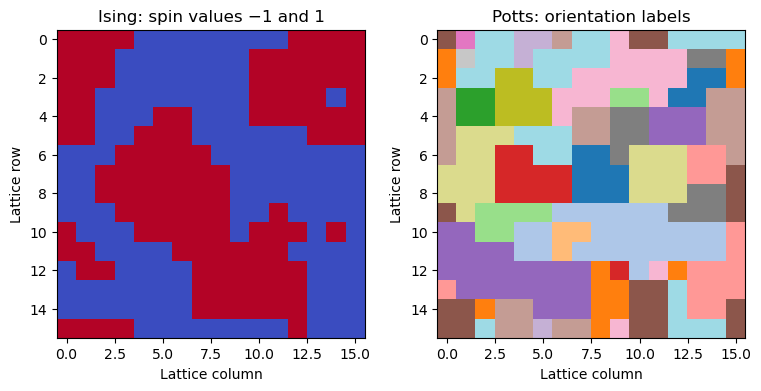

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(ising, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_title("Ising: spin values −1 and 1")
axes[1].imshow(potts, cmap="tab20")
axes[1].set_title("Potts: orientation labels")
for ax in axes:
    ax.set_xlabel("Lattice column")
    ax.set_ylabel("Lattice row")
plt.show()

## Step 5: Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/examples/monte_carlo.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.